### ENTREGA

In [2]:
import cv2
import mediapipe as mp
import numpy as np
from pathlib import Path
import time

In [20]:
# --------------------------------------------------
# RUTAS DE LOS ACCESORIOS
# --------------------------------------------------

carpeta = Path.cwd() / "accesorios"

ruta_sombrero = carpeta / "sombrero.png"
ruta_puro = carpeta / "puro.png"
ruta_bandana = carpeta / "bandadna.png"

# --------------------------------------------------
# CARGA DE IMAGENES
# --------------------------------------------------

def cargar_accesorio(ruta):
    imagen = cv2.imread(str(ruta), cv2.IMREAD_UNCHANGED)

    if imagen is None:
        print(f"No se ha encontrado: {ruta.name}")
        return None

    # Si la imagen no tiene transparencia, añadimos un canal alfa.
    if len(imagen.shape) == 3 and imagen.shape[2] == 3:
        imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2BGRA)

    return imagen


sombrero = cargar_accesorio(ruta_sombrero)
puro = cargar_accesorio(ruta_puro)
bandana = cargar_accesorio(ruta_bandana)
# Recortar el espacio transparente del puro.
if puro is not None:

    mascara = puro[:, :, 3]
    puntos = cv2.findNonZero(mascara)

    x, y, w, h = cv2.boundingRect(puntos)

    puro = puro[y:y+h, x:x+w]

# --------------------------------------------------
# SUPERPOSICION DE IMAGENES
# --------------------------------------------------

def superponer(imagen, accesorio, centro, ancho, angulo=0):

    if accesorio is None:
        return imagen

    alto_original, ancho_original = accesorio.shape[:2]

    # Mantener la proporcion original del accesorio.
    alto = int(alto_original * ancho / ancho_original)

    if ancho <= 0 or alto <= 0:
        return imagen

    accesorio = cv2.resize(accesorio, (ancho, alto))

    # Girar el accesorio para adaptarlo a la inclinacion de la cabeza.
    matriz = cv2.getRotationMatrix2D(
    (ancho // 2, alto // 2), -angulo, 1
    )

    accesorio = cv2.warpAffine(
        accesorio,
        matriz,
        (ancho, alto),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0, 0)
    )

    alto_img, ancho_img = imagen.shape[:2]

    # Coordenadas de la esquina superior izquierda.
    x = int(centro[0] - ancho / 2)
    y = int(centro[1] - alto / 2)

    # Recortar si el accesorio sale de los limites de la imagen.
    x1 = max(0, x)
    y1 = max(0, y)
    x2 = min(ancho_img, x + ancho)
    y2 = min(alto_img, y + alto)

    if x1 >= x2 or y1 >= y2:
        return imagen

    # Recortar tambien la imagen del accesorio.
    accesorio_recortado = accesorio[
        y1 - y:y2 - y,
        x1 - x:x2 - x
    ]

    # Separar los canales de color y transparencia.
    zona = imagen[y1:y2, x1:x2]

    alfa = accesorio_recortado[:, :, 3] / 255.0
    alfa = alfa[:, :, np.newaxis]

    colores = accesorio_recortado[:, :, :3]

    # Mezclar el accesorio con la imagen original.
    imagen[y1:y2, x1:x2] = (
        colores * alfa + zona * (1 - alfa)
    ).astype(np.uint8)

    return imagen

# --------------------------------------------------
# FILTRO DEL OESTE
# --------------------------------------------------

def filtro_oeste(imagen):

    # Convertir a float para realizar operaciones.
    resultado = imagen.astype(np.float32)

    # ------------------------------------------
    # TONO SEPIA
    # ------------------------------------------

    matriz_sepia = np.array([
        [0.272, 0.534, 0.131],
        [0.349, 0.686, 0.168],
        [0.393, 0.769, 0.189]
    ])

    resultado = cv2.transform(resultado, matriz_sepia)

    resultado = np.clip(resultado, 0, 255)

    # ------------------------------------------
    # CONTRASTE Y BRILLO
    # ------------------------------------------

    resultado = cv2.convertScaleAbs(
        resultado,
        alpha=1.15,
        beta=5
    )

    # ------------------------------------------
    # VIÑETEADO
    # ------------------------------------------

    alto, ancho = imagen.shape[:2]

    kernel_x = cv2.getGaussianKernel(ancho, ancho * 0.5)
    kernel_y = cv2.getGaussianKernel(alto, alto * 0.5)

    mascara = kernel_y @ kernel_x.T

    mascara = mascara / mascara.max()

    # Oscurecer ligeramente las esquinas.
    mascara = 0.55 + 0.45 * mascara

    resultado = (
        resultado.astype(np.float32) *
        mascara[:, :, np.newaxis]
    )

    # ------------------------------------------
    # GRANO CINEMATOGRAFICO
    # ------------------------------------------

    ruido = np.random.normal(
        0, 3, resultado.shape
    ).astype(np.float32)

    resultado = resultado + ruido

    return np.clip(resultado, 0, 255).astype(np.uint8)


# --------------------------------------------------
# DETECCION FACIAL
# --------------------------------------------------

modelo = Path.cwd() / "face_landmarker.task"

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

opciones = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(modelo)),
    running_mode=RunningMode.VIDEO,
    num_faces=1
)

face_landmarker = FaceLandmarker.create_from_options(opciones)


# --------------------------------------------------
# DETECCION DE MANOS
# --------------------------------------------------

modelo_manos = Path.cwd() / "hand_landmarker.task"

HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions

# --------------------------------------------------
# DETECCION DEL CUERPO
# --------------------------------------------------

modelo_pose = Path.cwd() / "pose_landmarker_lite.task"

PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions

opciones_pose = PoseLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=str(modelo_pose)
    ),
    running_mode=RunningMode.VIDEO,
    num_poses=1
)

pose_landmarker = PoseLandmarker.create_from_options(
    opciones_pose
)

opciones_manos = HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=str(modelo_manos)
    ),
    running_mode=RunningMode.VIDEO,
    num_hands=2
)

hand_landmarker = HandLandmarker.create_from_options(
    opciones_manos
)


# --------------------------------------------------
# CAPTURA DE VIDEO
# --------------------------------------------------

camara = cv2.VideoCapture(0)

if not camara.isOpened():
    print("No se ha podido acceder a la camara.")
    exit()

ultimo_timestamp = -1

# --------------------------------------------------
# ESTADO DEL PURO
# --------------------------------------------------

estado_puro = "boca"

tiempo_cerca = None

mano_alejada = False

tiempo_recogida = 0.9
tiempo_devolucion = 0.3

while True:

    correcto, frame = camara.read()

    if not correcto:
        break

    # Reflejar la imagen como si fuera un espejo.
    frame = cv2.flip(frame, 1)

    alto, ancho = frame.shape[:2]

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Convertir la imagen al formato de MediaPipe.
    mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb
    )

# Obtener una marca de tiempo creciente.
    timestamp_ms = max(
    int(time.monotonic() * 1000),
    ultimo_timestamp + 1
    )
    ultimo_timestamp = timestamp_ms

# Detectar los puntos faciales.
    resultados = face_landmarker.detect_for_video(
    mp_image,
    timestamp_ms
    )

    # Detectar las manos.
    resultados_manos = hand_landmarker.detect_for_video(
    mp_image,
    timestamp_ms
    )

    # Detectar los puntos del cuerpo.
    resultados_pose = pose_landmarker.detect_for_video(
    mp_image,
    timestamp_ms
    )

    if resultados.face_landmarks:

        cara = resultados.face_landmarks[0]

        # Obtener las coordenadas de un punto facial.
        def punto(indice):
            landmark = cara[indice]

            x = int(landmark.x * ancho)
            y = int(landmark.y * alto)

            return (x, y)

        # Puntos principales de la cara.
        frente = punto(6)
        barbilla = punto(152)

        lado_izquierdo = punto(234)
        lado_derecho = punto(454)

        comisura_izquierda = punto(88)
        comisura_derecha = punto(291)

        boca_superior = punto(13)

        # Anchura aproximada de la cara.
        ancho_cara = int(
            np.linalg.norm(
                np.array(lado_derecho) -
                np.array(lado_izquierdo)
            )
        )

        # Inclinacion de la cabeza.
        vector_cara = (
            np.array(lado_derecho) -
            np.array(lado_izquierdo)
        )

        angulo = np.degrees(
            np.arctan2(vector_cara[1], vector_cara[0])
        )

        # ------------------------------------------
        # SOMBRERO
        # ------------------------------------------

        if sombrero is not None:

            ancho_sombrero = int(ancho_cara * 2.2)

            alto_sombrero = int(
                sombrero.shape[0] *
                ancho_sombrero /
                sombrero.shape[1]
            )

            centro_sombrero = (
                frente[0],
                frente[1] - int(alto_sombrero * 0.45)
            )

            frame = superponer(
                frame,
                sombrero,
                centro_sombrero,
                ancho_sombrero,
                angulo
            )



        # ------------------------------------------
        # BANDANA
        # ------------------------------------------

        if resultados_pose.pose_landmarks and bandana is not None:

            pose = resultados_pose.pose_landmarks[0]

            # Obtener la posicion de los hombros.
            hombro_izquierdo = (
                int(pose[11].x * ancho),
                int(pose[11].y * alto)
            )

            hombro_derecho = (
                int(pose[12].x * ancho),
                int(pose[12].y * alto)
            )

            # Calcular la distancia entre los hombros.
            distancia_hombros = int(
                np.linalg.norm(
                    np.array(hombro_derecho) -
                    np.array(hombro_izquierdo)
                )
            )

            # Centro entre ambos hombros.
            centro_hombros = (
                int((hombro_izquierdo[0] + hombro_derecho[0]) / 2),
                int((hombro_izquierdo[1] + hombro_derecho[1]) / 2)
            )

            # Desplazar la bandana ligeramente hacia abajo.
            centro_bandana = (
                centro_hombros[0],
                centro_hombros[1] + int(distancia_hombros * 0.06)
            )

            ancho_bandana = int(distancia_hombros * 1.10)

            # Calcular la inclinacion de los hombros.
            vector_hombros = (
                np.array(hombro_derecho) -
                np.array(hombro_izquierdo)
            )

            angulo_bandana = np.degrees(
                np.arctan2(
                    vector_hombros[1],
                    -vector_hombros[0]
                )
            )

            frame = superponer(
                frame,
                bandana,
                centro_bandana,
                ancho_bandana,
                -angulo_bandana
            )

        
# ------------------------------------------
# PURO E INTERACCION CON LA MANO
# ------------------------------------------

        if puro is not None:

            # Tamaño del puro respecto a la cara.
            ancho_puro = int(ancho_cara * 0.45)

            alto_puro = int(
                puro.shape[0] * ancho_puro / puro.shape[1]
            )

            # Escala del accesorio.
            escala = ancho_puro / puro.shape[1]

            # Punto de anclaje: extremo apagado del puro.
            ancla_x = int(ancho_puro * 0.96)
            ancla_y = int(alto_puro * 0.04)

            # La comisura será el punto donde se sujeta el puro.
            destino = comisura_derecha

            # Calcular el centro de la imagen para colocar
            # el extremo apagado exactamente en la comisura.
            centro_puro_boca = (
                destino[0] - ancla_x + ancho_puro,
                destino[1] - ancla_y + alto_puro // 2
            )

            # ------------------------------------------
            # DETECTAR POSICION DE LA MANO
            # ------------------------------------------

            punto_mano = None

            if resultados_manos.hand_landmarks:

                distancia_minima = float("inf")

                for mano in resultados_manos.hand_landmarks:

                    # Punta del pulgar e indice.
                    pulgar = mano[4]
                    indice = mano[8]

                    # Punto medio entre ambos dedos.
                    x_mano = int((pulgar.x + indice.x) / 2 * ancho)
                    y_mano = int((pulgar.y + indice.y) / 2 * alto)

                    candidato = (x_mano, y_mano)

                    # Buscar la mano mas cercana al puro.
                    distancia = np.linalg.norm(
                        np.array(candidato) -
                        np.array(centro_puro_boca)
                    )

                    if distancia < distancia_minima:
                        distancia_minima = distancia
                        punto_mano = candidato

            # Distancia entre la mano y el puro en la boca.
            if punto_mano is not None:

                distancia_boca = np.linalg.norm(
                    np.array(punto_mano) -
                    np.array(centro_puro_boca)
                )

            else:
                distancia_boca = float("inf")

            tiempo_actual = time.monotonic()

            umbral = int(ancho_cara * 0.20)

            # ------------------------------------------
            # ESTADO 1: PURO EN LA BOCA
            # ------------------------------------------

            if estado_puro == "boca":

                if distancia_boca < umbral:

                    if tiempo_cerca is None:
                        tiempo_cerca = tiempo_actual

                    elif tiempo_actual - tiempo_cerca >= tiempo_recogida:

                        estado_puro = "mano"
                        mano_alejada = False
                        tiempo_cerca = None

                else:
                    tiempo_cerca = None

                # Mostrar el puro en su posicion original.
                if estado_puro == "boca":

                    frame = superponer(
                        frame,
                        puro,
                        centro_puro_boca,
                        ancho_puro,
                        0
                    )

            # ------------------------------------------
            # ESTADO 2: PURO EN LA MANO
            # ------------------------------------------

            elif estado_puro == "mano":

                if punto_mano is not None:

                    # Esperar a que la mano se aleje.
                    if distancia_boca > umbral * 1.8:
                        mano_alejada = True

                    # Comprobar si vuelve a acercarse a la boca.
                    if mano_alejada and distancia_boca < umbral:

                        if tiempo_cerca is None:
                            tiempo_cerca = tiempo_actual

                        elif tiempo_actual - tiempo_cerca >= tiempo_devolucion:

                            estado_puro = "boca"
                            mano_alejada = False
                            tiempo_cerca = None

                    else:
                        tiempo_cerca = None

                    # Mostrar el puro en la mano.
                    if estado_puro == "mano":

                        centro_puro_mano = (
                            punto_mano[0] + int(ancho_puro * 0.20),
                            punto_mano[1]
                        )

                        frame = superponer(
                            frame,
                            puro,
                            centro_puro_mano,
                            ancho_puro,
                            0
                        )

                else:
                    tiempo_cerca = None


    # Aplicar el filtro del Oeste.
    frame = filtro_oeste(frame)

    # Mostrar resultado.
    cv2.imshow("Filtro de vaquero", frame)

    # Salir pulsando ESC.
    if cv2.waitKey(1) & 0xFF == 27:
        break


# --------------------------------------------------
# LIBERAR RECURSOS
# --------------------------------------------------

camara.release()
face_landmarker.close()
pose_landmarker.close()
cv2.destroyAllWindows()


descarga, separacion y entrenamiento
pip install -q kagglehub

In [1]:
import kagglehub
from pathlib import Path

# descargar el dataset
ruta_descarga = Path(kagglehub.dataset_download("ananthu017/emotion-detection-fer"))

print("Dataset descargado en:", ruta_descarga)

# localizar las carpetas train y test
carpeta_train = None
carpeta_test = None

for ruta in ruta_descarga.rglob("*"):
    if ruta.is_dir():
        if ruta.name.lower() == "train":
            carpeta_train = ruta
        elif ruta.name.lower() == "test":
            carpeta_test = ruta

if carpeta_train is None or carpeta_test is None:
    raise FileNotFoundError("No se han encontrado las carpetas train y test.")

print("Carpeta de entrenamiento:", carpeta_train)
print("Carpeta de test:", carpeta_test)

# comprobar las clases disponibles
clases_train = sorted([c.name for c in carpeta_train.iterdir() if c.is_dir()])
clases_test = sorted([c.name for c in carpeta_test.iterdir() if c.is_dir()])

print("\nClases de entrenamiento:", clases_train)
print("Clases de test:", clases_test)

if clases_train != clases_test:
    raise ValueError("Las clases de train y test no coinciden.")

e:\uni\Anaconda\envs\VC_P5\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 65.2M/65.2M [00:02<00:00, 25.0MB/s]

Extracting files...


Dataset descargado en: C:\Users\paull\.cache\kagglehub\datasets\ananthu017\emotion-detection-fer\versions\1
Carpeta de entrenamiento: C:\Users\paull\.cache\kagglehub\datasets\ananthu017\emotion-detection-fer\versions\1\train
Carpeta de test: C:\Users\paull\.cache\kagglehub\datasets\ananthu017\emotion-detection-fer\versions\1\test

Clases de entrenamiento: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Clases de test: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']


In [2]:
import random
import shutil
from collections import Counter

# fijar semilla para reproducir la separacion
random.seed(42)

# carpeta donde guardaremos el dataset preparado
ruta_dataset = Path.cwd() / "dataset_emociones"

# evitar reconstruir accidentalmente una separacion anterior
if ruta_dataset.exists():
    raise FileExistsError(
        f"Ya existe {ruta_dataset}. No se ha modificado. "
        "Eliminala manualmente si quieres generar una nueva separacion."
    )

# crear carpetas principales
for conjunto in ["train", "val", "test"]:
    for clase in clases_train:
        (ruta_dataset / conjunto / clase).mkdir(parents=True, exist_ok=True)

# separar las imagenes originales de entrenamiento
for clase in clases_train:

    imagenes = [
        f for f in (carpeta_train / clase).iterdir()
        if f.is_file()
    ]

    random.shuffle(imagenes)

    limite = int(len(imagenes) * 0.8)

    imagenes_train = imagenes[:limite]
    imagenes_val = imagenes[limite:]

    # copiar imagenes de entrenamiento
    for imagen in imagenes_train:
        shutil.copy2(imagen, ruta_dataset / "train" / clase / imagen.name)

    # copiar imagenes de validacion
    for imagen in imagenes_val:
        shutil.copy2(imagen, ruta_dataset / "val" / clase / imagen.name)

    print(f"{clase}: {len(imagenes_train)} train, {len(imagenes_val)} val")

# copiar el conjunto de test original sin dividirlo
for clase in clases_test:

    imagenes = [
        f for f in (carpeta_test / clase).iterdir()
        if f.is_file()
    ]

    for imagen in imagenes:
        shutil.copy2(imagen, ruta_dataset / "test" / clase / imagen.name)

print("\nSeparacion completada.")

# mostrar distribucion final
for conjunto in ["train", "val", "test"]:
    print(f"\n{conjunto.upper()}")

    for clase in clases_train:
        cantidad = len(list((ruta_dataset / conjunto / clase).glob("*")))
        print(f"{clase}: {cantidad}")

angry: 3196 train, 799 val
disgusted: 348 train, 88 val
fearful: 3277 train, 820 val
happy: 5772 train, 1443 val
neutral: 3972 train, 993 val
sad: 3864 train, 966 val
surprised: 2536 train, 635 val

Separacion completada.

TRAIN
angry: 3196
disgusted: 348
fearful: 3277
happy: 5772
neutral: 3972
sad: 3864
surprised: 2536

VAL
angry: 799
disgusted: 88
fearful: 820
happy: 1443
neutral: 993
sad: 966
surprised: 635

TEST
angry: 958
disgusted: 111
fearful: 1024
happy: 1774
neutral: 1233
sad: 1247
surprised: 831


Found 22965 images belonging to 7 classes.
Found 5744 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.
Clases: {'angry': 0, 'disgusted': 1, 'fearful': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprised': 6}

Pesos de las clases:
angry: 1.027
disgusted: 9.427
fearful: 1.001
happy: 0.568
neutral: 0.826
sad: 0.849
surprised: 1.294


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 12, 12, 128)    │             

 Total params: 1,276,647 (4.87 MB)

 Trainable params: 1,273,959 (4.86 MB)

 Non-trainable params: 2,688 (10.50 KB)

Epoch 1/100
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.1530 - loss: 2.6705
Epoch 1: val_loss improved from None to 2.39948, saving model to f:\Ingenieria Informática - ULPGC\QUINTO - ASIGNATURAS\VC\VC_P5\VC_P5\models\mejor_modelo_v2.keras

Epoch 1: finished saving model to f:\Ingenieria Informática - ULPGC\QUINTO - ASIGNATURAS\VC\VC_P5\VC_P5\models\mejor_modelo_v2.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 99s 259ms/step - accuracy: 0.1530 - loss: 2.6705 - val_accuracy: 0.0806 - val_loss: 2.3995 - learning_rate: 3.0000e-04
Epoch 2/100
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.1610 - loss: 2.3938
Epoch 2: val_loss improved from 2.39948 to 2.06761, saving model to f:\Ingenieria Informática - ULPGC\QUINTO - ASIGNATURAS\VC\VC_P5\VC_P5\models\mejor_modelo_v2.keras

Epoch 2: finished saving model to f:\Ingenieria Informática - ULPGC\QUINTO - ASIGNATURAS\VC\VC_P5\VC_P5\models\mejor_modelo_v2.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 93s 258ms/step - accuracy: 0.1610 - loss: 2.39

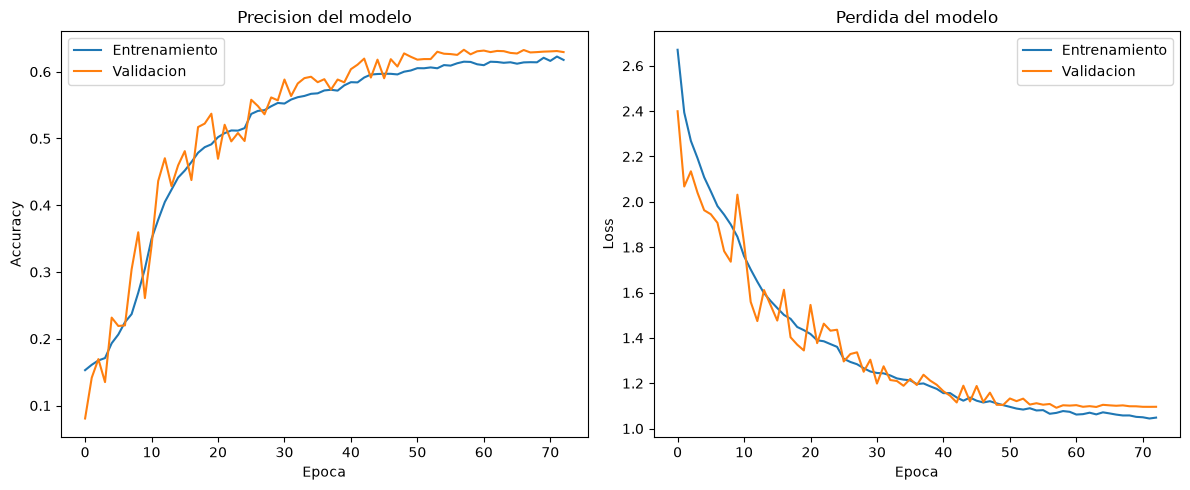

113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.6291 - loss: 1.1021

Test loss: 1.1021
Test accuracy: 0.6291
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step

Informe de clasificacion:
              precision    recall  f1-score   support

       angry       0.57      0.55      0.56       958
   disgusted       0.36      0.69      0.48       111
     fearful       0.54      0.26      0.35      1024
       happy       0.88      0.82      0.85      1774
     neutral       0.51      0.74      0.60      1233
         sad       0.52      0.47      0.50      1247
   surprised       0.72      0.82      0.76       831

    accuracy                           0.63      7178
   macro avg       0.59      0.62      0.59      7178
weighted avg       0.64      0.63      0.62      7178



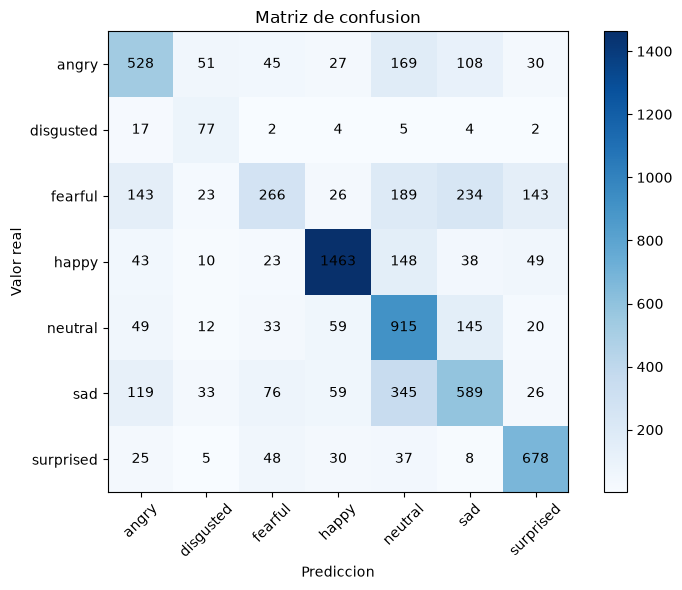

In [5]:

import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Dense, Dropout,
    BatchNormalization, Activation, GlobalAveragePooling2D
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

# --------------------------------------------------
# CONFIGURACION
# --------------------------------------------------

IMG_SIZE = 48
BATCH_SIZE = 64
EPOCHS = 100

tf.keras.utils.set_random_seed(42)

ruta_dataset = Path.cwd() / "dataset_emociones"
ruta_modelos = Path.cwd() / "models"
ruta_modelos.mkdir(exist_ok=True)

# archivos de la segunda version
ruta_mejor_modelo = ruta_modelos / "mejor_modelo_v2.keras"
ruta_modelo_final = ruta_modelos / "modelo_emociones_v2.keras"
ruta_clases = ruta_modelos / "clases_v2.json"

clases = sorted([
    c.name for c in (ruta_dataset / "train").iterdir()
    if c.is_dir()
])

# --------------------------------------------------
# GENERADORES DE IMAGENES
# --------------------------------------------------

# aumentacion de datos para entrenamiento
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

# validacion y test sin aumentacion
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    ruta_dataset / "train",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=clases,
    shuffle=True
)

val_generator = test_datagen.flow_from_directory(
    ruta_dataset / "val",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=clases,
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    ruta_dataset / "test",
    target_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=clases,
    shuffle=False
)

print("Clases:", train_generator.class_indices)

# --------------------------------------------------
# PESOS DE LAS CLASES
# --------------------------------------------------

pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)

class_weights = {
    int(clase): float(peso)
    for clase, peso in zip(np.unique(train_generator.classes), pesos)
}

print("\nPesos de las clases:")

for clase, indice in train_generator.class_indices.items():
    print(f"{clase}: {class_weights[indice]:.3f}")

# --------------------------------------------------
# CONSTRUCCION DE LA CNN
# --------------------------------------------------

model = Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

    # bloque convolucional 1
    Conv2D(32, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    Conv2D(32, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),
    Dropout(0.20),

    # bloque convolucional 2
    Conv2D(64, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    Conv2D(64, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # bloque convolucional 3
    Conv2D(128, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    Conv2D(128, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),
    Dropout(0.30),

    # bloque convolucional 4
    Conv2D(256, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    Conv2D(256, (3, 3), padding="same", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),
    Dropout(0.35),

    # clasificador
    GlobalAveragePooling2D(),

    Dense(256, activation="relu", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(128, activation="relu", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.4),

    Dense(len(clases), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# --------------------------------------------------
# CALLBACKS
# --------------------------------------------------

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        ruta_mejor_modelo,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# --------------------------------------------------
# ENTRENAMIENTO
# --------------------------------------------------

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

# --------------------------------------------------
# CARGAR Y GUARDAR EL MEJOR MODELO
# --------------------------------------------------

model = load_model(ruta_mejor_modelo)

model.save(ruta_modelo_final)

# guardar las clases para utilizarlas posteriormente
with open(ruta_clases, "w") as f:
    json.dump(clases, f)

print("\nModelos guardados correctamente:")
print(ruta_mejor_modelo)
print(ruta_modelo_final)
print(ruta_clases)

# --------------------------------------------------
# GRAFICAS DE ENTRENAMIENTO
# --------------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validacion")
plt.title("Precision del modelo")
plt.xlabel("Epoca")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validacion")
plt.title("Perdida del modelo")
plt.xlabel("Epoca")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# EVALUACION CON TEST
# --------------------------------------------------

test_generator.reset()

loss, accuracy = model.evaluate(test_generator)

print(f"\nTest loss: {loss:.4f}")
print(f"Test accuracy: {accuracy:.4f}")

# predicciones
predicciones = model.predict(test_generator)
y_pred = np.argmax(predicciones, axis=1)
y_real = test_generator.classes

print("\nInforme de clasificacion:")
print(classification_report(
    y_real,
    y_pred,
    target_names=clases,
    zero_division=0
))

# matriz de confusion
matriz = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(matriz, cmap="Blues")
plt.title("Matriz de confusion")
plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.xticks(range(len(clases)), clases, rotation=45)
plt.yticks(range(len(clases)), clases)
plt.colorbar()

for i in range(len(clases)):
    for j in range(len(clases)):
        plt.text(j, i, matriz[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()
